In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
url = "https://api.slingacademy.com/v1/sample-data/files/student-scores.json"

response = requests.get(url, timeout=30)

if response.status_code == 200:
    data = response.json()
    print("Student data fetched successfully!")
    print("Total records:", len(data))
    print("Sample record:")
    print(data[0])
else:
    print("API request failed:", response.status_code)

Student data fetched successfully!
Total records: 2000
Sample record:
{'id': 1, 'first_name': 'Paul', 'last_name': 'Casey', 'email': 'paul.casey.1@gslingacademy.com', 'gender': 'male', 'part_time_job': False, 'absence_days': 3, 'extracurricular_activities': False, 'weekly_self_study_hours': 27, 'career_aspiration': 'Lawyer', 'math_score': 73, 'history_score': 81, 'physics_score': 93, 'chemistry_score': 97, 'biology_score': 63, 'english_score': 80, 'geography_score': 87}


In [4]:
# Convert API data into a DataFrame
df = pd.DataFrame(data)

# Select the subject columns
subjects = [
    "math_score",
    "history_score",
    "physics_score",
    "chemistry_score",
    "biology_score",
    "english_score",
    "geography_score"
]

# Calculate each student's average score
df["average_score"] = df[subjects].mean(axis=1)

# Display the first 10 students
print(df[["first_name", "last_name", "average_score"]].head(10))

# Calculate the overall class average
class_average = df["average_score"].mean()

print("\nOverall Class Average:", round(class_average, 2))

  first_name  last_name  average_score
0       Paul      Casey      82.000000
1   Danielle   Sandoval      91.428571
2       Tina    Andrews      86.428571
3       Tara      Clark      78.714286
4    Anthony     Campos      74.428571
5      Kelly       Wade      82.000000
6    Anthony      Smith      84.714286
7     George      Short      82.000000
8    Stanley  Gutierrez      81.142857
9     Audrey    Simpson      76.714286

Overall Class Average: 80.98


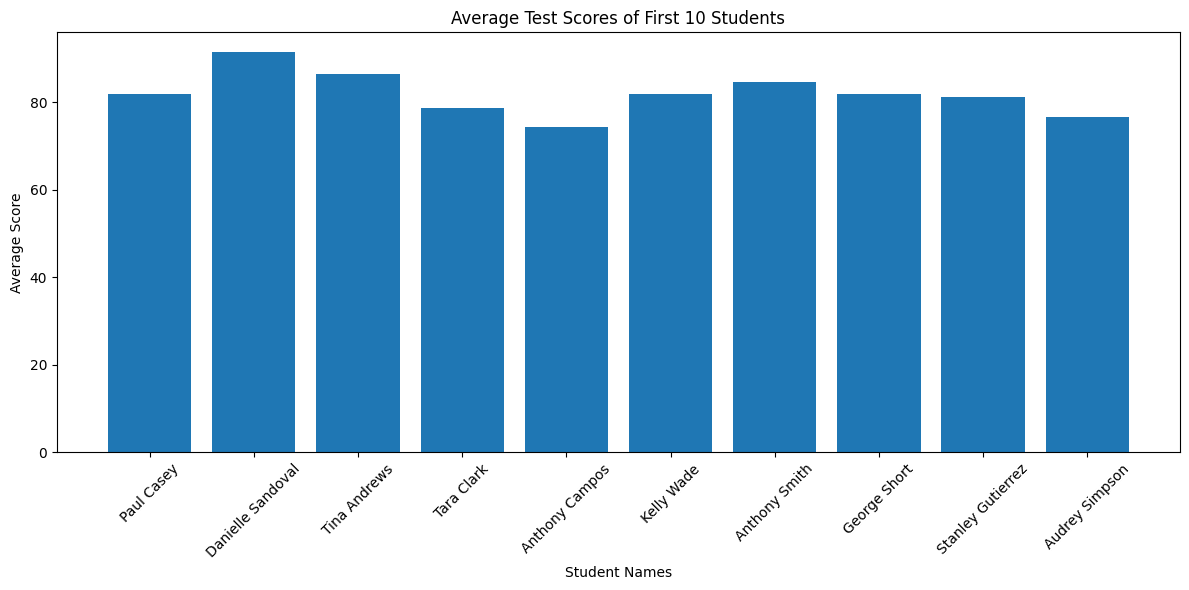

In [5]:
# Select the first 10 students for the chart
chart_data = df.head(10)

student_names = (
    chart_data["first_name"] + " " + chart_data["last_name"]
)

plt.figure(figsize=(12, 6))

plt.bar(student_names, chart_data["average_score"])

plt.xlabel("Student Names")
plt.ylabel("Average Score")
plt.title("Average Test Scores of First 10 Students")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()